Today's topics:

* checking a chatbot's values against a measurement
* reporting AI-generated values
* training data, licenses, privacy, and AI policy
* checking an AI assistant's figure against the data

# Germanium on silicon

Today we will finish our germanium on silicon example, look at the law around language models, and check a figure an AI assistant wrote.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/b/bd/Molecular-beam_epitaxy_412_RIBER_system_at_LAAS-CNRS.jpg/960px-Molecular-beam_epitaxy_412_RIBER_system_at_LAAS-CNRS.jpg" alt="A molecular-beam epitaxy system, a stainless steel vacuum chamber with many ports, flanges, cooling lines and cables, standing in a cleanroom laboratory" width=480/>

*Photo by QGravelier, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Molecular-beam_epitaxy_412_RIBER_system_at_LAAS-CNRS.jpg).*

Above: A [molecular-beam epitaxy](https://en.wikipedia.org/wiki/Molecular-beam_epitaxy) system, like the one from our critical thickness example.

To get the lattice mismatch $f$ for germanium on silicon we need both lattice constants.

$$f = \frac{a_f - a_s}{a_s}$$

We asked a chatbot for them.

## Recap

**Inference from the weights:** the model writes values from what it learned in training.
Nothing is looked up.

**Tool call:** the model asks a tool to search or run code, then writes from the result.

Our saved reply is from Claude Haiku 5.5 and has no search step.
It cites the CRC Handbook, but nothing was looked up.

Here is the saved reply as a table.
The blank thermal conductivity for carbon becomes `np.nan`.

In [1]:
import numpy as np
import pandas as pd
from io import StringIO  # reads a CSV from text

In [2]:
llm = pd.DataFrame({
    'symbol': ['Fe', 'Cu', 'Al', 'Ni', 'Ti', 'W', 'Si', 'Ge', 'Mo', 'Sn', 'C', 'Mn'],
    'structure': ['BCC (alpha)', 'FCC', 'FCC', 'FCC', 'HCP (alpha)', 'BCC',
                  'Diamond cubic', 'Diamond cubic', 'BCC', 'Tetragonal (white tin)',
                  'Hexagonal (graphite)', 'Cubic (alpha-Mn)'],
    'lattice_constant': [2.866, 3.615, 4.050, 3.524, 2.951, 3.165,
                         5.431, 5.658, 3.147, 5.832, 2.464, 8.913],  # angstroms
    'thermal_conductivity': [80.4, 401, 237, 90.9, 21.9, 173,
                             149, 60.2, 138, 66.6, np.nan, 7.81],  # W/(m K)
})
display(llm)

,symbol,structure,lattice_constant,thermal_conductivity
0,Fe,BCC (alpha),2.866,80.40
1,Cu,FCC,3.615,401.00
2,Al,FCC,4.050,237.00
3,Ni,FCC,3.524,90.90
4,Ti,HCP (alpha),2.951,21.90
5,W,BCC,3.165,173.00
6,Si,Diamond cubic,5.431,149.00
7,Ge,Diamond cubic,5.658,60.20
8,Mo,BCC,3.147,138.00
9,Sn,Tetragonal (white tin),5.832,66.60


The full request, the saved reply, and the model explanation are in Lecture 33.
Appendix A shows how to run this notebook on your own reply.

# Graphite or diamond?

In our saved reply, carbon is graphite.

In [3]:
display(llm[llm['symbol'] == 'C'])

,symbol,structure,lattice_constant,thermal_conductivity
10,C,Hexagonal (graphite),2.464,NaN


Graphite has $a = 2.464$ angstroms ([AIST crystal database](https://unit.aist.go.jp/mmri/ja/organization/db-nomura/common/struc-coord/C%28Graphite%29-c.html)).
Diamond has $a = 3.567$ angstroms ([Hom, Kiszenik, and Post, 1975](https://doi.org/10.1107/S0021889875010965)).

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/f/f0/Graphite-and-diamond-with-scale.jpg/960px-Graphite-and-diamond-with-scale.jpg" alt="A dark graphite specimen on the left and a small translucent diamond crystal on the right, with a 5 mm scale bar" width=480/>

*Photo by Robert M. Lavinsky, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Graphite-and-diamond-with-scale.jpg).*

Our request just said C.
So each model had to pick a crystal.

## Where a number comes from

The model writes from its weights and the current input.
Our saved reply names no page or table we could check.
So we compare with a measurement of the same material under the same conditions.

# Back to germanium on silicon

Let's compute the mismatch from the chatbot's numbers and from a measurement.

`.iloc[0]` takes the single value out of a one-row selection:

In [4]:
si = llm[llm['symbol'] == 'Si']
ge = llm[llm['symbol'] == 'Ge']

a_si = si['lattice_constant'].iloc[0]
a_ge = ge['lattice_constant'].iloc[0]
print('chatbot:', (a_ge - a_si) / a_si)

print('measured:', (5.657820 - 5.430941) / 5.430941)  # Hom et al. (1975), at 25 C

chatbot: 0.04179709077517958
measured: 0.04177526509678531


The measured line uses lattice constants from X-ray diffraction, corrected to 25 degrees Celsius ([Hom, Kiszenik, and Post, 1975](https://doi.org/10.1107/S0021889875010965)).

Both give 0.0418, or 4.2%.
We report the measured number, because we can cite Hom et al.

That is almost 50 times the germanium on gallium arsenide mismatch (0.09%) from our critical thickness example.
This larger mismatch limits the thickness of germanium layers on silicon that grow without dislocations.

## Writing it up

Here is how we could report what we did:

> **Data note.** Lattice constants for 12 elements were generated by Claude Haiku 5.5 on November 15, 2026, from the prompt in Lecture 33, and were not used as measurements.
> For carbon the reply gave graphite.
> The mismatch of germanium on silicon, 4.2%, uses the measured lattice constants of Hom et al. (1975).

The syllabus says AI use must be documented.
A data note like this one is how we do that for numbers.

# Language models and the law

Who can use the training data, the model, our input, and the output?
We will take five questions in order.

* Training data and copyright
* Licenses for weights and for outputs
* Privacy and student records
* Academic integrity
* Responsibility for what we report

This is teaching, not legal advice.
Where the law is not settled, we will say so.

## Training data and copyright

Models are trained on web pages, books, code, and papers collected at enormous scale.
Much of that text is copyrighted.
In the US, **fair use** lets someone use copyrighted work without permission in some cases.
A court weighs the purpose of the use and its effect on the market for the original.

**Bartz v. Anthropic** (N.D. Cal., June 2025)

* The judge held that training on the authors' books was fair use on that record.
* Downloading and keeping a library of pirated books was not.
* Not a final word on language models.
  Anthropic had a petition to appeal pending when the case settled.

**The settlement is separate from the ruling.**

* Anthropic agreed to a class settlement of $1.5 billion.
  The court gave final approval on July 20, 2026.
* It pays authors of the listed books about $3,000 per work.
* It releases claims about past copying of those books.
  It does not release claims about outputs or conduct from August 25, 2025 on.
* It does not require deleting any model.
  The court called objectors' requests for that beyond the scope of the settlement.

A settlement is a deal between the parties, so it is not a court ruling that training is legal or illegal.

**Thomson Reuters v. Ross** (3rd Cir., September 29, 2026)

* Ross trained a search tool with memos built from Westlaw headnotes, which are editors' summaries of points of law in court opinions.
  The ruling covers 2,243 headnotes.
* The tool was **not generative**.
  It only returned passages from existing court opinions.
* The headnotes were original enough to be copyrighted, and the tool was meant to compete with Westlaw.
* On appeal, the court agreed with the trial court that Ross's use of the headnotes was not fair use.

**Not settled.**
The court noted that Ross's tool does not generate new expression, so the case does not decide generative models.
Whether training a generative language model is fair use is still open.

**Facts and compilations** (*Feist v. Rural Telephone*, US Supreme Court, 1991)

* Facts are not copyrightable.
* An original selection or arrangement of facts can be, with thin protection.

A measured lattice constant is a fact.
A commercial database's text and layout can be protected.
A license or terms of use can restrict copying even where copyright does not.

*The New York Times v. OpenAI and Microsoft* is a pending case in federal court in New York.
Its fair use question is **not settled**.

## Licenses for weights and outputs

Two different things have terms attached.

* **The weights** are a file.
  Open-weight models let us download them under a license.
* **The outputs** from a chat or API are covered by the provider's terms of service.

**Example: Llama 3.1** (Meta, July 23, 2024), summarized.
The conditions have exact wording, so we read the license itself, and Meta's Acceptable Use Policy is a separate document.

* A free license to use, copy, modify, and distribute the model.
* A company with more than 700 million monthly active users must ask Meta for a license.
* Attribution and naming rules apply when we redistribute the model or build on it.
* Use must follow Meta's Acceptable Use Policy.

**Example: Apache 2.0**

* Some open-weight models use this standard license.
* It grants copyright rights to copy, modify, and distribute.
* It does not grant use of the licensor's trademarks.
* It provides the work "AS IS", without warranties.

Open weights do not mean open training data.
Newer Llama releases use different license text, so we read the license of the exact version we use.

## Privacy and student records

**FERPA** is the federal law that protects students' education records.

One route to sharing student information without consent is the **school official** exception.
The US Department of Education says it applies to an online tool only if the tool:

* does a service the school would otherwise do itself
* is under the school's direct control over use and maintenance of the data
* is used as the school's annual notice says
* does not re-disclose the data or use it for other purposes

The same page tells teachers to check first with administration and IT whether a tool is approved.
So the practical rule is: use only tools the university has approved for that kind of data.

Penn State's [AI data protection page](https://ai.psu.edu/ai-literacy/data-protection) says which data may go into which AI tools.
Our syllabus bars uploading "copyrighted course materials or sensitive research data" into any AI tool.

Samsung engineers reportedly pasted semiconductor source code into ChatGPT in 2023.
Samsung then restricted generative AI tools on company devices.

## Academic integrity

The course policy is in the syllabus under Generative AI.

**Homework:** AI tools may be used freely, and you must

* document your use, including the prompts and how you adapted the output
* critically evaluate AI-generated code
* be able to explain your submitted work

**Quizzes and exams:** no electronic devices of any kind.

The syllabus also says

* "You are fully responsible for the integrity, accuracy, and originality of your submitted work."
* Failing to cite and disclose AI use "constitutes plagiarism under Penn State's Academic Integrity policy".
* Uploading completed labs or homework to any generative AI tool is a violation of the course copyright policy.

Our data note from earlier is the kind of disclosure that policy asks for.

## Responsibility for what we report

**Fabrication.**
Reporting a generated number as if we measured it is fabrication.
We say which AI tool we used, when, and what we did with its output.

**Who is responsible.**
The author who reports the number, not the chatbot.
Provider terms commonly say the output may be wrong, so we read them for the tool we use.

**Retention and training settings.**
A company may keep our chats or train its next model on them.
The options differ by provider and plan.
We check them before pasting anything.

**Who owns an output.**
*Thaler v. Vidal* (Federal Circuit, 2022) is about patents.
The Patent Act's "inventor" must be a person, so an AI system cannot be named as the inventor.
The court did not decide whether a person who used AI can be an inventor.
*Thaler v. Perlmutter* (D.C. Circuit, 2025) is about copyright.
It upheld refusing registration for a work its claimant said the machine authored on its own.
The court said this does not bar copyright for work made with AI assistance.
Which AI-assisted works qualify is **not settled**.

## Algorithmic disgorgement

What happens to a model built on data that was collected or used improperly?

This is a privacy remedy, not a copyright rule.
The US Federal Trade Commission (FTC) alleged that Everalbum used face recognition on users' photos without proper consent.
In a consent order, Everalbum agreed to delete:

* photos and videos from users who had deactivated their accounts
* face embeddings made without users' express consent
* any models or algorithms developed in whole or in part from biometric information collected from its app's users

Commentators call this remedy **algorithmic disgorgement**.

The New York Times reportedly asked for something similar as relief in its copyright suit.
That request is a claim, not a ruling, and the copyright question is not settled.

So for every training set we write down where it came from and its license.

## Questions for discussion

Whole-class discussion.
We will take as many as time allows.

1. A company trains a model to predict alloy hardness.
   Its training data include a supplier's test results, shared under a license that forbids using them to train models.
   A court orders the company to stop using the data and the models trained on them.
   Why would deleting the supplier's rows from the training table fail to comply?
   What should the team have recorded about each data source?
2. A student pastes unpublished data from a sponsored project into a chatbot to clean it up.
   Who could see those data, and what agreements could this break?
3. A teaching assistant pastes a spreadsheet of student names, ID numbers, and quiz scores into a free chatbot account to draft a grade summary.
   Which rules from today apply?
   What could the assistant have done instead?
4. A chatbot suggests a new alloy composition.
   A research group makes it, tests it, and finds it works.
   Can the chatbot be named as an inventor?
   What would we need to know about what each researcher contributed?
5. Measured property values are facts.
   Can we copy a commercial materials database to train a model?
   What besides copyright decides this?

# Checking an assistant's figure

A battery delivers less power in the cold.
One cause is the electrolyte, the liquid that moves lithium ions between the electrodes.
Its conductivity falls as it cools.
These are measured conductivities of LiPF$_6$ in a mix of two carbonate solvents, at 15 temperatures and 14 salt concentrations ([Ding, 2003](https://doi.org/10.1021/je020219o), via [CALiSol-23](https://doi.org/10.1038/s41597-024-03575-8)).
The concentration is a **molality**: moles of salt per kilogram of solvent.

In [5]:
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/electrolyte_conductivity_lipf6.csv'
electrolyte = pd.read_csv(url)
display(electrolyte)

,temperature_K,molality_mol_per_kg,conductivity_mS_per_cm
0,194.15,0.2705,0.03099
1,194.15,0.3855,0.02794
2,194.15,0.4648,0.02438
3,194.15,0.5547,0.01968
4,194.15,0.6541,0.01492
...,...,...,...
205,332.15,1.4766,11.34000
206,332.15,1.7117,10.33000
207,332.15,1.9198,9.18000
208,332.15,2.1166,8.32300


## The request

An AI coding assistant can write plotting code in seconds.
Here is the request:

> I have a pandas DataFrame called `electrolyte` with the columns `temperature_K`, `molality_mol_per_kg`, and `conductivity_mS_per_cm`. It holds the ionic conductivity of a lithium-ion battery electrolyte (LiPF6 salt) measured at 15 temperatures and 14 salt concentrations. Write Python code with matplotlib that makes a publication-quality figure of conductivity against molality, with one series per temperature. The DataFrame is already loaded, so don't load any data. Reply with the code and a short explanation.

The reply below came from Claude Haiku 5.5 on November 15, 2026.
It ran inside the tools we use to build this course.
So it knew one of our habits: we leave out `plt.show()`.

Here is the main part of its explanation, word for word:

> Here is a matplotlib script that plots conductivity against molality, with one line per temperature coloured by temperature (viridis) and the legend outside the axes.
>
> Why it is built this way:
> - Temperature is an ordered quantity, so one sequential colormap (viridis) runs from cool to warm and the reader can see the trend across lines.
> - The legend sits outside the plot so the 15 lines are not hidden behind it.
> - Each line is sorted by molality so it does not zigzag, and small markers show the measured points without cluttering the figure.
> - The colormap is truncated at 0.9 so the palest yellow does not wash out against white.
> - The PDF is vector with editable text, and the PNG is at 600 dpi for slides or a manuscript.
> - There is no `plt.show()`, as you prefer.

And here is its code, unchanged.
It uses tools we have not covered, and that is normal for assistant code.

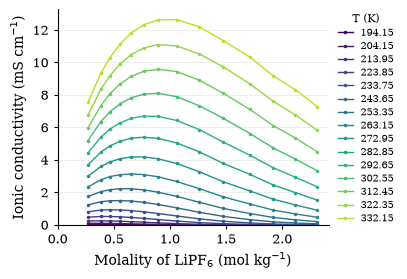

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.linewidth": 0.8,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "legend.frameon": False,
    "legend.fontsize": 7,
    "legend.title_fontsize": 8,
    "savefig.dpi": 600,
    "pdf.fonttype": 42,  # keep text editable in vector output
})

cmap = plt.colormaps["viridis"]
temps = np.sort(electrolyte["temperature_K"].unique())
norm = Normalize(vmin=temps.min(), vmax=temps.max())

fig, ax = plt.subplots(figsize=(3.5, 2.8))  # single-column width

for T in temps:
    sub = (electrolyte[electrolyte["temperature_K"] == T]
           .dropna(subset=["molality_mol_per_kg", "conductivity_mS_per_cm"])
           .sort_values("molality_mol_per_kg"))
    # Truncate the colormap so the palest yellow end stays visible on white
    color = cmap(0.9 * norm(T))
    ax.plot(sub["molality_mol_per_kg"], sub["conductivity_mS_per_cm"],
            color=color, lw=1.0, marker="o", ms=2.5, mec="none",
            label=f"{T:g}")

ax.set_xlabel(r"Molality of LiPF$_6$ (mol kg$^{-1}$)")
ax.set_ylabel(r"Ionic conductivity (mS cm$^{-1}$)")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="0.9", lw=0.5)
ax.set_axisbelow(True)

ax.legend(title="T (K)", loc="upper left", bbox_to_anchor=(1.02, 1),
          borderaxespad=0, handlelength=1.5, labelspacing=0.3)

fig.savefig("conductivity_vs_molality.pdf", bbox_inches="tight")
fig.savefig("conductivity_vs_molality.png", bbox_inches="tight")

The labels have units.
The colors run in order.
It saved two files.

`plt.rcParams.update` also changed the defaults for every later figure in this notebook, like the serif font.
`plt.rcdefaults()` restores Matplotlib's default settings:

In [7]:
plt.rcdefaults()

What range of conductivities does the figure have to show?

In [8]:
print(electrolyte['conductivity_mS_per_cm'].min())
print(electrolyte['conductivity_mS_per_cm'].max())

9.03e-07
12.64


From about $10^{-6}$ to 12.6 mS/cm: seven orders of magnitude.
Check the assistant's axis against those numbers, not against how the figure looks:

In [9]:
print(ax.get_yscale())
print(ax.get_ylim())

linear
(np.float64(0.0), np.float64(13.271999954850001))


The axis is linear and runs from 0 to about 13.
Everything below about 0.1 mS/cm sits on the bottom of the plot, so the cold series cannot be read.

A log axis gives each factor of 10 the same space.
A log axis cannot start at 0.
We switch the assistant's axis to log and set limits that cover the minimum and maximum:

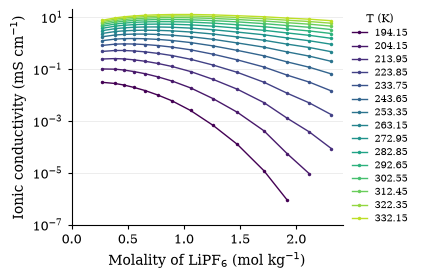

In [10]:
ax.set_yscale('log')
ax.set_ylim(1e-7, 20)  # mS/cm, limits covering the data
fig

On Friday we ask an assistant in AI Studio to run code on a figure and data.
Then we check what it returns.
When a check fails, we revise the request.

# Summary

* Inference from the weights and tool calls
* Generated values versus measured values
* Data notes for AI-generated values
* Fair use and training data
* Licenses for model weights and terms for outputs
* FERPA and sensitive data in AI tools
* Disclosure and responsibility for AI output
* Algorithmic disgorgement
* Checking an assistant's figure against the data: axis scale, limits versus minimum and maximum

# Quiz 10 warm-up

In Q1 you will:
- read two `dropna` filters and say why a row is removed,
- say what filling missing values with a number would claim about the data.

In Q2 you will:
- read a calculation on values a chatbot wrote,
- explain how such values are generated and how they can be reported.

## Further reading

* Google Machine Learning Crash Course, [Introduction to large language models](https://developers.google.com/machine-learning/crash-course/llm)
* *Thomson Reuters v. Ross Intelligence*, No. 25-2153 (3d Cir. Sept. 29, 2026), [opinion](https://www.govinfo.gov/content/pkg/USCOURTS-ca3-25-02153/pdf/USCOURTS-ca3-25-02153-0.pdf)
* *Bartz v. Anthropic*, No. 3:24-cv-05417 (N.D. Cal. July 20, 2026), [order granting final approval of class settlement](https://cdn.arstechnica.net/wp-content/uploads/2026/07/Bartz-v-Anthropic-Order-Approving-Settlement-7-20-26.pdf)
* *Feist Publications v. Rural Telephone Service*, 499 U.S. 340 (1991), [opinion](https://www.law.cornell.edu/supremecourt/text/499/340)
* *Thaler v. Perlmutter*, No. 23-5233 (D.C. Cir. Mar. 18, 2025), [opinion](https://media.cadc.uscourts.gov/opinions/docs/2025/03/23-5233.pdf)
* *Thaler v. Vidal*, No. 21-2347 (Fed. Cir. Aug. 5, 2022), [opinion](https://law.justia.com/cases/federal/appellate-courts/cafc/21-2347/21-2347-2022-08-05.html)
* FTC, [Everalbum consent order](https://www.ftc.gov/system/files/documents/cases/everalbum_order.pdf) (2021)
* US Department of Education, [FERPA and online tools in a course](https://studentprivacy.ed.gov/faq/i-want-use-online-tool-or-application-part-my-course-however-i-am-worried-it-violation-ferpa)
* Penn State, [AI data protection](https://ai.psu.edu/ai-literacy/data-protection)
* Matplotlib, [Axis scales](https://matplotlib.org/stable/gallery/scales/scales.html)
* Meta, [Llama 3.1 Community License](https://raw.githubusercontent.com/meta-llama/llama-models/main/models/llama3_1/LICENSE) and [Apache License 2.0](https://www.apache.org/licenses/LICENSE-2.0.txt)

# Appendix A: Using your own reply

To run this notebook on your own reply, set `LIVE_MODE = True`.
Paste the element rows of your reply under the header line, inside the triple quotes.
Leave out your reply's own header row and any text around the table.

Run this cell, then rerun the cells from "Graphite or diamond?" down.
The text describes the saved reply, so your numbers will differ.

In [11]:
LIVE_MODE = False  # True: use your own reply from AI Studio

pasted_reply = """
symbol,structure,lattice_constant,thermal_conductivity,source
"""

if LIVE_MODE:
    # index_col=False drops extra commas at the end of a row
    llm = pd.read_csv(StringIO(pasted_reply), index_col=False)
    # text like '5.43 A' becomes NaN
    llm['lattice_constant'] = pd.to_numeric(llm['lattice_constant'], errors='coerce')
    llm['thermal_conductivity'] = pd.to_numeric(llm['thermal_conductivity'], errors='coerce')
    display(llm)